# Full pipeline

Neural Network-Driven Signal Generation for Systematic Portfolio Construction (MScFE 690 Capstone).

This notebook holds no logic of its own. Each step calls a module in `src/` and shows the result. Settings are in `config.yaml`.

In [1]:
import os, sys

if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Joebasshd/nn-etf-portfolio-signals.git repo
    %cd repo
    !pip install -q -r requirements.txt

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data, evaluate, features, models, portfolio, signals, splits, stats

cfg = data.load_config(ROOT / "config.yaml")
RUN_LABEL = "src-full-quick" if cfg["run"]["quick_mode"] else "src-full"
clock = evaluate.start_clock()
cfg["run"]

{'quick_mode': False,
 'quick': {'lstm_seeds': 2,
  'lstm_max_epochs': 2,
  'lightgbm_n_estimators': 200},
 'results_dir': 'results'}

## 1. Data

Yahoo prices and FRED macro series, cached in `data/raw`. In quick mode the prices are generated instead.

In [3]:
if cfg["run"]["quick_mode"]:
    prices, macro = data.make_synthetic(cfg, n_days=3400)
else:
    prices, macro = data.load_data(cfg)

print(f"{len(prices)} trading days, {prices.index.min().date()} to {prices.index.max().date()}")
macro.dropna().tail()

6661 trading days, 2000-01-03 to 2026-06-29


,DTB3,VIX,TERM_SPREAD
date,,,
2026-06-23,3.70,17.28,0.66
2026-06-24,3.70,19.49,0.65
2026-06-25,3.70,18.63,0.56
2026-06-26,3.69,18.89,0.56
2026-06-29,3.67,18.41,0.55


In [4]:
out = evaluate.results_dir(cfg, RUN_LABEL)
FIG = out / "figures"
print(f"Results: {out}")

Results: /Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/results/2026-10-31_4c11a4d_src-full


## 2. Features and label

31 indicators per ETF. The label for a decision at the close of day t is the return from the close of t+1 to the close of t+6.

In [5]:
dataset = features.build_dataset(prices, macro, cfg)
feature_cols = features.feature_columns(dataset)

print(f"{len(dataset):,} rows, {len(feature_cols)} features")
dataset[feature_cols].describe().T[["mean", "std", "min", "max"]].round(3)

70,398 rows, 31 features


,mean,std,min,max
trend_sma10_ratio,0.002,0.022,-0.278,0.245
trend_sma20_ratio,0.003,0.032,-0.415,0.250
trend_sma50_ratio,0.009,0.051,-0.523,0.382
trend_sma200_ratio,0.035,0.099,-0.613,0.434
trend_macd_line,0.002,0.015,-0.301,0.061
trend_macd_signal,0.002,0.015,-0.239,0.055
trend_macd_hist,0.000,0.005,-0.104,0.061
trend_adx,22.632,8.627,5.214,69.483
mom_ret_5d,0.002,0.030,-0.346,0.348
mom_ret_21d,0.009,0.059,-0.557,0.568


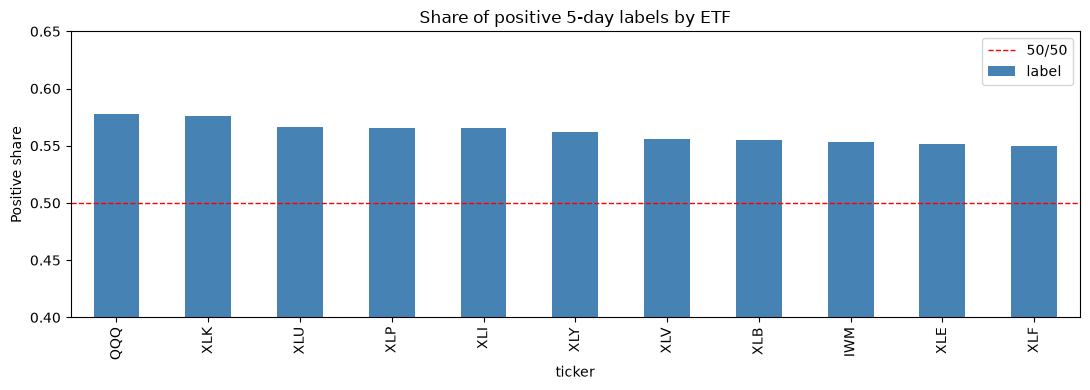

In [6]:
balance = dataset.groupby("ticker")["label"].mean().sort_values(ascending=False)

ax = balance.plot(kind="bar", color="steelblue", figsize=(11, 4), ylim=(0.4, 0.65))
ax.axhline(0.5, color="red", linestyle="--", linewidth=1, label="50/50")
ax.set_title("Share of positive 5-day labels by ETF")
ax.set_ylabel("Positive share")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Walk-forward splits

Training expands by one year at each step. Validation is the 12 months ending 11 trading days before the test year, and training ends 11 trading days before validation (1 execution lag + 5 horizon + 5 embargo), so each test year is complete.

In [7]:
folds = splits.walk_forward_splits(prices.index, cfg)

pd.DataFrame(
    [
        {
            "test_year": s.test_year,
            "train_start": s.train.min().date(),
            "train_end": s.train.max().date(),
            "validation_start": s.validation.min().date(),
            "validation_end": s.validation.max().date(),
            "test_start": s.test.min().date(),
            "test_end": s.test.max().date(),
        }
        for s in folds
    ]
).set_index("test_year")

,train_start,train_end,validation_start,validation_end,test_start,test_end
test_year,,,,,,
2008,2001-01-02,2006-11-28,2006-12-14,2007-12-13,2008-01-02,2008-12-31
2009,2001-01-02,2007-11-29,2007-12-17,2008-12-15,2009-01-02,2009-12-31
2010,2001-01-02,2008-11-28,2008-12-16,2009-12-15,2010-01-04,2010-12-31
2011,2001-01-02,2009-11-30,2009-12-16,2010-12-15,2011-01-03,2011-12-30
2012,2001-01-02,2010-11-29,2010-12-15,2011-12-14,2012-01-03,2012-12-31
2013,2001-01-02,2011-11-28,2011-12-14,2012-12-13,2013-01-02,2013-12-31
2014,2001-01-02,2012-11-28,2012-12-14,2013-12-13,2014-01-02,2014-12-31
2015,2001-01-02,2013-11-27,2013-12-16,2014-12-15,2015-01-02,2015-12-31
2016,2001-01-02,2014-11-28,2014-12-16,2015-12-15,2016-01-04,2016-12-30


## 4. Models

In every window LASSO (L1) and LightGBM (top 15 by gain) only select features. The ridge (L2) logistic regression, LightGBM and the LSTM all forecast from the union of the two selections. The code key `lasso` is the ridge forecasting fit, labelled "Linear (L1 selection, ridge on union)". One LSTM per seed, plus the seed-averaged forecast.

In [8]:
result = models.run_walk_forward(dataset, folds, cfg)
names = evaluate.display_names(result.probabilities.columns)
labels = dataset["label"]
print(f"{len(result.probabilities):,} test rows | models: {', '.join(names.values())}")
result.tuning

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticn

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use '

...

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticn

/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


51,161 test rows | models: Linear (L1 selection, ridge on union), LightGBM, LSTM, LSTM (seed 43), LSTM (seed 44), LSTM (seed 45), LSTM (seed 46), LSTM (seed 47), LSTM (seed 48), LSTM (seed 49), LSTM (seed 50), LSTM (seed 51), LSTM (average of 10 seeds)


,lasso_C,ridge_C,n_lasso,n_union
test_year,,,,
2008,0.050,0.00300,21,26
2009,0.005,0.00030,4,15
2010,0.002,0.00001,2,16
2011,0.005,0.00001,8,20
2012,0.005,0.00030,7,16
2013,0.005,0.00001,5,19
2014,0.010,0.00010,12,19
2015,0.050,0.10000,25,26
2016,0.002,0.00010,1,15


In [9]:
tuning_edges = models.grid_edges(result.tuning, cfg)
tuning_edges

,grid,windows,at_lower_edge,at_upper_edge,chosen
parameter,,,,,
lasso_C,"[0.002, 0.005, 0.01, 0.05, 0.1]",19,6,1,0.002: 6; 0.005: 5; 0.01: 2; 0.05: 5; 0.1: 1
ridge_C,"[1e-05, 3e-05, 0.0001, 0.0003, 0.001, 0.003, 0...",19,7,1,1e-05: 7; 0.0001: 4; 0.0003: 2; 0.003: 1; 0.01...


## 5. Signals

Main signal `s = min(1, max(0, (p − b) / (p90 − b)))`, with `b` from the training block and `p90` from validation forecasts. A model stays flat for a whole window when `p90 − b` is below the floor. The base-rate centred and `2p − 1` signals are sensitivity versions for the three main models.

In [10]:
main_signals = signals.scaled_signal(result.probabilities, result.window_stats, cfg)
main_models = signals.main_models(cfg)
sensitivity = {
    "base_rate": signals.base_rate_centred_signal(result.probabilities[main_models], result.window_stats),
    "linear": signals.linear_signal(result.probabilities[main_models]),
}
edges = signals.signal_edges(result.window_stats, cfg).reset_index().assign(model=lambda e: e["model"].map(names))
flat = edges[edges["flat"]]
print(f"Flat windows: {len(flat)}")
print(flat.groupby("model")["test_year"].apply(list).to_string() if len(flat) else "none")
edges.pivot(index="test_year", columns="model", values="edge")[list(names.values())].round(4)

Flat windows: 18
model
LightGBM                                 [2010, 2011, 2013, 2014, 2016, 2018, 2021, 202...
Linear (L1 selection, ridge on union)           [2010, 2011, 2013, 2017, 2019, 2021, 2024]


model,"Linear (L1 selection, ridge on union)",LightGBM,LSTM,LSTM (seed 43),LSTM (seed 44),LSTM (seed 45),LSTM (seed 46),LSTM (seed 47),LSTM (seed 48),LSTM (seed 49),LSTM (seed 50),LSTM (seed 51),LSTM (average of 10 seeds)
test_year,,,,,,,,,,,,,
2008,0.0748,0.0826,0.1070,0.1107,0.0837,0.1185,0.0958,0.0856,0.1125,0.1264,0.1165,0.1347,0.0945
2009,0.0174,0.0670,0.0665,0.0257,0.0239,0.0425,0.1096,0.0402,0.0522,0.0559,0.0983,0.0532,0.0387
2010,0.0008,0.0040,0.1399,0.1604,0.0439,0.1180,0.1059,0.0601,0.1381,0.1103,0.0212,0.1366,0.0842
2011,0.0020,0.0037,0.0928,0.0170,0.0562,0.0440,0.0490,0.0540,0.0315,0.0418,0.0594,0.0496,0.0349
2012,0.0185,0.0130,0.0268,0.0396,0.0654,0.0490,0.0534,0.0309,0.0357,0.0384,0.0849,0.0410,0.0303
2013,0.0040,0.0012,0.0584,0.0513,0.0751,0.0447,0.0610,0.0614,0.0681,0.0669,0.0490,0.0868,0.0481
2014,0.0189,0.0085,0.0282,0.0411,0.0204,0.0454,0.0339,0.0407,0.0527,0.0471,0.0646,0.0709,0.0374
2015,0.0416,0.0996,0.0835,0.2039,0.1679,0.0762,0.0723,0.0556,0.1471,0.0720,0.0960,0.0431,0.0799
2016,0.0129,0.0041,0.0338,0.0410,0.1327,0.0745,0.0373,0.0509,0.0631,0.0542,0.0855,0.0591,0.0541


## 6. Portfolio and benchmarks

Inverse-volatility weights scaled to 10% forecast volatility, capped at 25% per ETF, no leverage, cash at the T-bill rate. Weekly decisions, traded at the next close, 2-point no-trade band per ETF, 5 bps per side. Every strategy and benchmark goes through the same backtest.

In [11]:
market = portfolio.prepare_market(prices, macro, cfg, result.probabilities.index.get_level_values("date").min())
base = portfolio.base_weights(market, cfg)
strategies = evaluate.strategy_targets(main_signals, sensitivity, base, market, cfg, names)
results = portfolio.run_strategies(strategies, market, cfg)
common = next(iter(results.values())).index
performance = evaluate.performance_table(results, market.rf)
print(f"Backtest: {common[0].date()} to {common[-1].date()}, {len(common)} days")
performance.style.format({"Ann. return": "{:.2%}", "Ann. volatility": "{:.2%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}",
                          "Max drawdown": "{:.2%}", "Turnover / yr": "{:.1f}x", "Avg exposure": "{:.0%}"})

Backtest: 2008-02-04 to 2026-06-29, 4629 days


,Ann. return,Ann. volatility,Sharpe,Sortino,Max drawdown,Turnover / yr,Avg exposure
SPY buy-and-hold,11.56%,19.81%,0.58,0.82,-51.48%,0.0x,100%
Equal-weight (monthly),11.14%,19.01%,0.58,0.81,-50.68%,0.1x,98%
Vol-targeted SPY,7.69%,10.87%,0.61,0.83,-21.14%,1.2x,70%
SMA 50/200 rule,8.33%,12.49%,0.59,0.81,-31.18%,1.3x,75%
Always-on (vol-scaled),7.56%,11.23%,0.58,0.79,-23.73%,0.7x,75%
"Linear (L1 selection, ridge on union)",2.22%,5.53%,0.18,0.24,-19.94%,3.9x,20%
"Linear (L1 selection, ridge on union), base-rate",2.04%,1.07%,0.62,0.86,-3.34%,0.0x,6%
"Linear (L1 selection, ridge on union), 2p-1",2.32%,1.86%,0.51,0.69,-6.56%,0.0x,10%
LightGBM,2.21%,3.30%,0.26,0.38,-12.13%,3.1x,8%
"LightGBM, base-rate",1.46%,0.27%,0.33,0.46,-0.76%,0.1x,1%


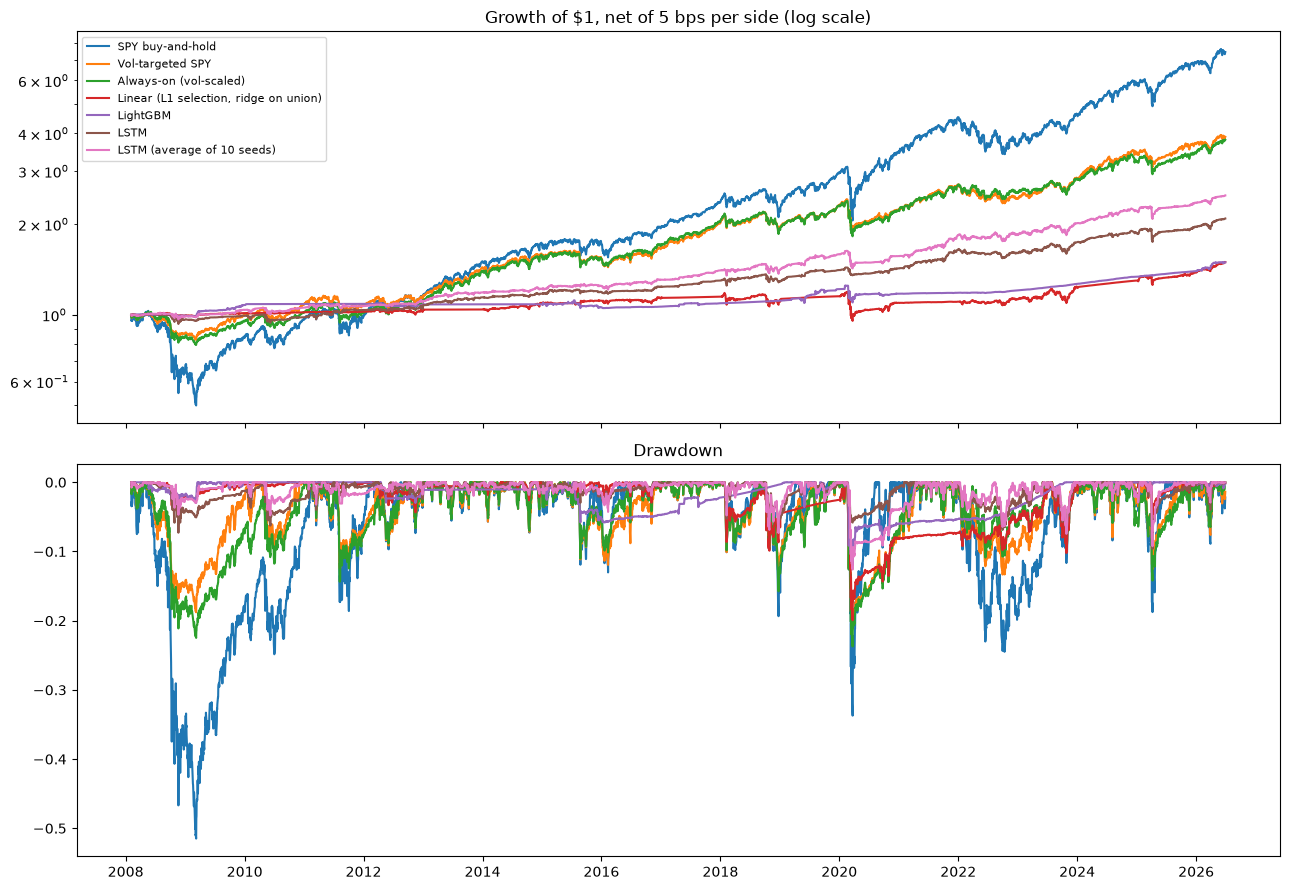

In [12]:
shown = ["SPY buy-and-hold", "Vol-targeted SPY", "Always-on (vol-scaled)", names["lasso"], names["lightgbm"],
         names[main_models[2]]] + ([names["lstm_avg"]] if "lstm_avg" in names else [])
fig, ax = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for name in shown:
    equity = (1 + results[name]["ret"]).cumprod()
    ax[0].plot(equity, label=name)
    ax[1].plot(equity / equity.cummax() - 1, label=name)
ax[0].set_yscale("log")
ax[0].set_title(f"Growth of $1, net of {cfg['portfolio']['cost_bps_per_side']} bps per side (log scale)")
ax[0].legend(fontsize=8)
ax[1].set_title("Drawdown")
plt.tight_layout()
fig.savefig(FIG / "equity_drawdown.png", dpi=120)
plt.show()

In [13]:
cost_names = ["Always-on (vol-scaled)", "SMA 50/200 rule"] + list(names.values())
costs = evaluate.cost_sensitivity({n: strategies[n] for n in cost_names}, market, cfg, common)
costs.round(2)

,Sharpe @ 0 bps,Sharpe @ 2 bps,Sharpe @ 5 bps,Sharpe @ 10 bps,Break-even cost (bps)
Always-on (vol-scaled),0.59,0.59,0.58,0.58,937.35
SMA 50/200 rule,0.60,0.60,0.59,0.59,562.14
"Linear (L1 selection, ridge on union)",0.21,0.20,0.18,0.14,30.08
LightGBM,0.31,0.29,0.26,0.22,32.61
LSTM,0.60,0.58,0.54,0.47,47.31
LSTM (seed 43),0.67,0.64,0.59,0.52,46.98
LSTM (seed 44),0.55,0.53,0.49,0.43,43.77
LSTM (seed 45),0.70,0.67,0.63,0.57,54.10
LSTM (seed 46),0.76,0.73,0.70,0.64,61.25
LSTM (seed 47),0.74,0.72,0.68,0.61,54.55


## 7. Prediction quality

Accuracy against the base rate, AUC, Brier score and log loss on every labelled test row. Calibration is analysis only: forecasts are binned by deciles of p.

In [14]:
prediction = evaluate.prediction_metrics(result.probabilities, labels, names)
prediction.round(4)

,n,base_rate,accuracy,AUC,Brier,Brier (base rate),log_loss,mean_p,sd_p
model,,,,,,,,,
"Linear (L1 selection, ridge on union)",51095,0.5698,0.5665,0.4956,0.2465,0.2451,0.6863,0.5555,0.0342
LightGBM,51095,0.5698,0.5670,0.5059,0.2459,0.2451,0.6850,0.5486,0.0335
LSTM,51095,0.5698,0.5460,0.5053,0.2490,0.2451,0.6915,0.5559,0.0639
LSTM (seed 43),51095,0.5698,0.5501,0.5045,0.2495,0.2451,0.6928,0.5535,0.0699
LSTM (seed 44),51095,0.5698,0.5485,0.5053,0.2490,0.2451,0.6914,0.5621,0.0671
LSTM (seed 45),51095,0.5698,0.5523,0.5101,0.2490,0.2451,0.6918,0.5655,0.0667
LSTM (seed 46),51095,0.5698,0.5540,0.5157,0.2474,0.2451,0.6881,0.5618,0.0632
LSTM (seed 47),51095,0.5698,0.5631,0.5141,0.2464,0.2451,0.6861,0.5624,0.0590
LSTM (seed 48),51095,0.5698,0.5508,0.5085,0.2485,0.2451,0.6904,0.5583,0.0677


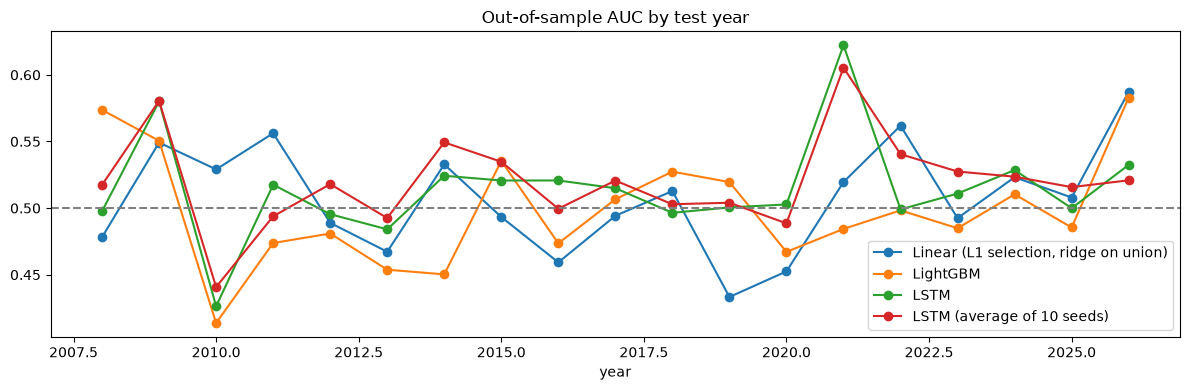

,"Linear (L1 selection, ridge on union)",LightGBM,LSTM,LSTM (seed 43),LSTM (seed 44),LSTM (seed 45),LSTM (seed 46),LSTM (seed 47),LSTM (seed 48),LSTM (seed 49),LSTM (seed 50),LSTM (seed 51),LSTM (average of 10 seeds)
year,,,,,,,,,,,,,
2008,0.4782,0.5737,0.4976,0.5025,0.5026,0.5030,0.5123,0.5332,0.5218,0.5204,0.5196,0.5264,0.5174
2009,0.5492,0.5505,0.5800,0.5478,0.4826,0.4733,0.5825,0.5835,0.5879,0.6264,0.5642,0.5737,0.5805
2010,0.5291,0.4137,0.4263,0.4380,0.4571,0.4600,0.4670,0.4768,0.4640,0.4312,0.5203,0.4587,0.4408
2011,0.5561,0.4738,0.5176,0.4598,0.4869,0.5203,0.4944,0.5279,0.4408,0.4994,0.5030,0.4630,0.4938
2012,0.4889,0.4809,0.4954,0.5194,0.4735,0.5123,0.5304,0.5221,0.5237,0.5649,0.4891,0.5013,0.5180
2013,0.4672,0.4538,0.4841,0.4536,0.5447,0.5249,0.5050,0.4255,0.4950,0.4895,0.4973,0.4906,0.4925
2014,0.5328,0.4503,0.5243,0.5334,0.4939,0.5331,0.5975,0.5524,0.5402,0.5452,0.5350,0.5021,0.5493
2015,0.4933,0.5354,0.5207,0.5136,0.5302,0.5147,0.5356,0.4903,0.5423,0.5060,0.5219,0.5205,0.5348
2016,0.4593,0.4735,0.5207,0.5136,0.4978,0.5236,0.4485,0.4739,0.4784,0.4898,0.5165,0.5140,0.4995


In [15]:
auc_year = evaluate.auc_by_year(result.probabilities, labels, names)
ax = auc_year[[names[m] for m in main_models] + ([names["lstm_avg"]] if "lstm_avg" in names else [])].plot(
    marker="o", figsize=(12, 4), title="Out-of-sample AUC by test year")
ax.axhline(0.5, color="grey", linestyle="--")
plt.tight_layout()
ax.figure.savefig(FIG / "auc_by_year.png", dpi=120)
plt.show()
auc_year.round(4)

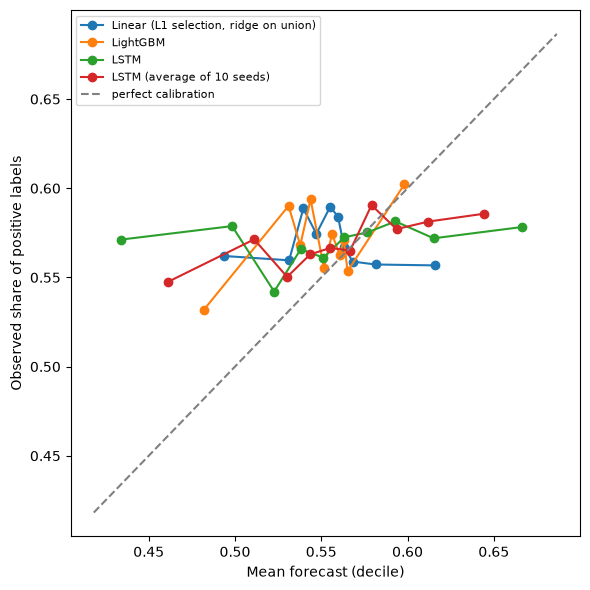

In [16]:
calibration = evaluate.calibration_table(result.probabilities, labels, names, cfg["stats"]["calibration_bins"])
fig, ax = plt.subplots(figsize=(6, 6))
for name in [names[m] for m in main_models] + ([names["lstm_avg"]] if "lstm_avg" in names else []):
    t = calibration[calibration["model"] == name]
    ax.plot(t["mean_p"], t["observed"], marker="o", label=name)
lims = [calibration[["mean_p", "observed"]].min().min(), calibration[["mean_p", "observed"]].max().max()]
ax.plot(lims, lims, color="grey", linestyle="--", label="perfect calibration")
ax.set_xlabel("Mean forecast (decile)")
ax.set_ylabel("Observed share of positive labels")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "calibration.png", dpi=120)
plt.show()

## 8. Indicator stability

How often each indicator is selected, the average Jaccard overlap between consecutive windows, and the share of selected indicators by family.

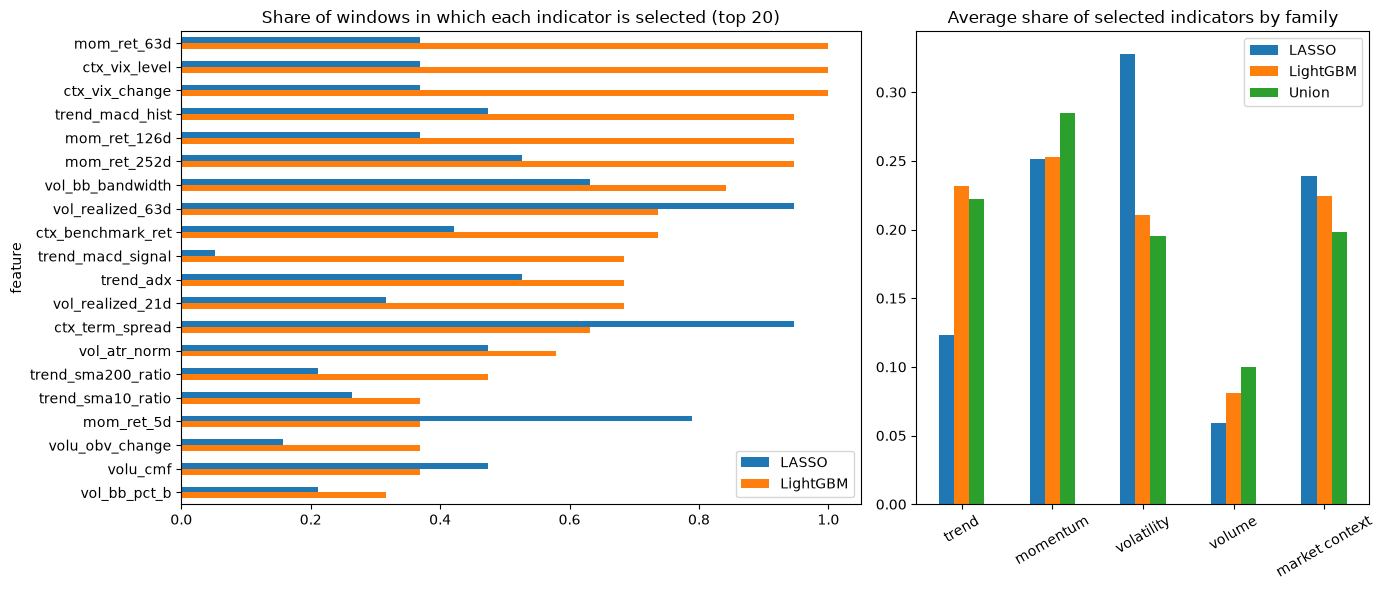

,avg. indicators selected,avg. overlap (Jaccard),most selected family,most selected indicator
model,,,,
LASSO,11.526316,0.339993,volatility,vol_realized_63d (95% of windows)
LightGBM,15.000000,0.604131,momentum,mom_ret_63d (100% of windows)
Union,20.000000,0.597848,momentum,mom_ret_63d (100% of windows)


In [17]:
frequency = evaluate.selection_frequency(result.selections, feature_cols)
families = evaluate.family_share(result.selections)
stability = evaluate.stability_summary(result.selections, feature_cols)
fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [3, 2]})
frequency[["LASSO", "LightGBM"]].head(20).plot.barh(ax=ax[0], title="Share of windows in which each indicator is selected (top 20)")
ax[0].invert_yaxis()
families.plot.bar(ax=ax[1], rot=30, title="Average share of selected indicators by family")
plt.tight_layout()
fig.savefig(FIG / "selection_stability.png", dpi=120)
plt.show()
stability

## 9. Significance

**Sharpe differences.** Stationary block bootstrap, with the HAC Ledoit–Wolf (2008) test next to it. H4: every LSTM seed and the seed average against the linear model and LightGBM, Holm-corrected across the two. LSTM vs LightGBM is the substantive test; LSTM vs linear is reported but not interpreted, because the linear model finds no usable signal.

In [18]:
sharpe_tests = stats.sharpe_tests(results, market.rf, names, cfg)
sharpe_tests.round(4)

,Sharpe A,Sharpe B,Difference,95% CI low,95% CI high,"p (A > B, one-sided)",LW difference,LW std. error,LW z,"LW p (A > B, one-sided)",p Holm (H4),Use
"LSTM vs Linear (L1 selection, ridge on union)",0.5369,0.1768,0.3601,-0.0172,0.7133,0.0308,0.3602,0.1730,2.0822,0.0187,0.0616,"H4, reported but not interpreted (linear finds..."
LSTM vs LightGBM,0.5369,0.2633,0.2736,-0.2617,0.7357,0.1603,0.2736,0.2753,0.9940,0.1601,0.1603,"H4, substantive test"
"LSTM (seed 43) vs Linear (L1 selection, ridge on union)",0.5948,0.1768,0.4180,0.1134,0.7335,0.0048,0.4181,0.1756,2.3803,0.0086,0.0096,"H4, reported but not interpreted (linear finds..."
LSTM (seed 43) vs LightGBM,0.5948,0.2633,0.3315,-0.1209,0.7608,0.0723,0.3315,0.2564,1.2931,0.0980,0.0723,"H4, substantive test"
"LSTM (seed 44) vs Linear (L1 selection, ridge on union)",0.4892,0.1768,0.3124,0.0148,0.5944,0.0203,0.3124,0.1619,1.9301,0.0268,0.0406,"H4, reported but not interpreted (linear finds..."
LSTM (seed 44) vs LightGBM,0.4892,0.2633,0.2259,-0.2570,0.6664,0.1766,0.2259,0.2669,0.8463,0.1987,0.1766,"H4, substantive test"
"LSTM (seed 45) vs Linear (L1 selection, ridge on union)",0.6332,0.1768,0.4564,0.1089,0.7657,0.0053,0.4564,0.1679,2.7188,0.0033,0.0106,"H4, reported but not interpreted (linear finds..."
LSTM (seed 45) vs LightGBM,0.6332,0.2633,0.3699,-0.1412,0.8133,0.0753,0.3699,0.2759,1.3409,0.0900,0.0753,"H4, substantive test"
"LSTM (seed 46) vs Linear (L1 selection, ridge on union)",0.6973,0.1768,0.5205,0.1850,0.8327,0.0007,0.5206,0.1844,2.8230,0.0024,0.0014,"H4, reported but not interpreted (linear finds..."
LSTM (seed 46) vs LightGBM,0.6973,0.2633,0.4340,-0.0484,0.8599,0.0390,0.4340,0.2710,1.6014,0.0546,0.0390,"H4, substantive test"


**Exposure-matched placebo.** Each draw circularly shifts the model's actual weekly signals (independent: one shift per ETF; common: one shift for all ETFs) and runs them through the same backtest and costs. Exposure and holding lengths are kept; timing is not.

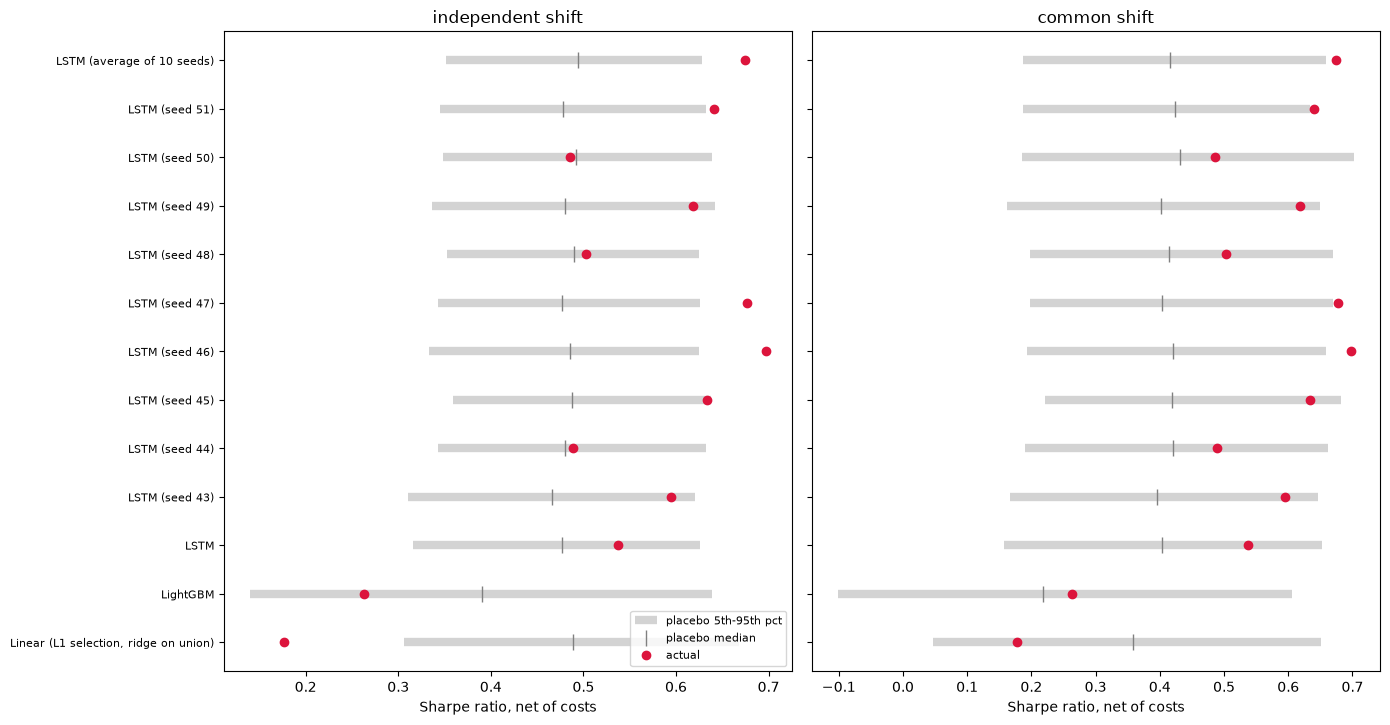

,,Actual Sharpe,Placebo median,Placebo 5th pct,Placebo 95th pct,p (placebo >= actual),Actual max drawdown,Placebo median max drawdown,Actual exposure,Placebo mean exposure,Draws
model,variant,,,,,,,,,,
"Linear (L1 selection, ridge on union)",independent,0.177,0.488,0.307,0.668,0.994,-0.199,-0.071,0.195,0.191,1000.0
LightGBM,independent,0.263,0.390,0.139,0.638,0.799,-0.121,-0.029,0.076,0.075,1000.0
LSTM,independent,0.537,0.477,0.316,0.626,0.258,-0.096,-0.089,0.251,0.248,1000.0
LSTM (seed 43),independent,0.595,0.466,0.311,0.621,0.085,-0.129,-0.087,0.250,0.246,1000.0
LSTM (seed 44),independent,0.489,0.480,0.343,0.632,0.465,-0.119,-0.095,0.261,0.258,1000.0
LSTM (seed 45),independent,0.633,0.487,0.359,0.638,0.057,-0.091,-0.103,0.288,0.289,1000.0
LSTM (seed 46),independent,0.697,0.485,0.334,0.625,0.008,-0.091,-0.091,0.269,0.258,1000.0
LSTM (seed 47),independent,0.677,0.477,0.343,0.626,0.012,-0.098,-0.095,0.275,0.268,1000.0
LSTM (seed 48),independent,0.503,0.490,0.353,0.625,0.437,-0.183,-0.098,0.281,0.273,1000.0


In [19]:
placebo, placebo_draws = stats.run_placebo(main_signals, base, market, cfg, common, performance, names)
labels_shown = list(names.values())
variants = cfg["stats"]["placebo"]["variants"]
fig, axes = plt.subplots(1, len(variants), figsize=(7 * len(variants), 0.45 * len(labels_shown) + 1.5), sharey=True, squeeze=False)
for ax, variant in zip(axes.ravel(), variants):
    t = placebo.xs(variant, level="variant").reindex(labels_shown)
    y = np.arange(len(labels_shown))
    ax.hlines(y, t["Placebo 5th pct"], t["Placebo 95th pct"], color="lightgrey", lw=6, label="placebo 5th-95th pct")
    ax.plot(t["Placebo median"], y, "|", color="grey", ms=12, label="placebo median")
    ax.plot(t["Actual Sharpe"], y, "o", color="crimson", label="actual")
    ax.set_yticks(y)
    ax.set_yticklabels(labels_shown, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(f"{variant} shift")
    ax.set_xlabel("Sharpe ratio, net of costs")
axes.ravel()[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
fig.savefig(FIG / "placebo_sharpe.png", dpi=120)
plt.show()
placebo.round(3)

**Deflated Sharpe ratio.** 25 trials: the 10 current ones (9 main specifications and the seed average) from this run, the 15 historical ones from the frozen `dsr_trials.csv` of the reference run. A DSR above 0.95 is significant at 5%.

In [20]:
trials = stats.dsr_trials(performance, names, main_models, cfg)
dsr = stats.dsr_table(results, market.rf, list(names.values()) + ["Always-on (vol-scaled)"], trials)
print(f"{trials.notna().sum()} trials | SR0 = {dsr['SR0 (annualised)'].iloc[0]:.3f} (annualised)")
dsr.round(3)

25 trials | SR0 = 0.334 (annualised)


,Sharpe,Skew,Kurtosis,DSR,SR0 (annualised),Trials
"Linear (L1 selection, ridge on union)",0.177,-1.760,51.807,0.252,0.334,25
LightGBM,0.263,-0.370,142.163,0.382,0.334,25
LSTM,0.537,-0.544,34.336,0.804,0.334,25
LSTM (seed 43),0.595,-1.563,38.426,0.860,0.334,25
LSTM (seed 44),0.489,-1.813,35.774,0.740,0.334,25
LSTM (seed 45),0.633,-0.570,16.540,0.897,0.334,25
LSTM (seed 46),0.697,-0.949,31.558,0.935,0.334,25
LSTM (seed 47),0.677,-0.545,30.276,0.925,0.334,25
LSTM (seed 48),0.503,-2.753,58.456,0.754,0.334,25
LSTM (seed 49),0.619,-1.498,43.599,0.880,0.334,25


**Diebold–Mariano.** Brier loss averaged across ETFs each day, one-sided (does the LSTM have lower loss?), with Newey–West variance over horizon − 1 lags and the Harvey–Leybourne–Newbold correction.

In [21]:
diebold_mariano = stats.diebold_mariano_tests(stats.forecast_losses(result.probabilities, labels), names, cfg)
diebold_mariano.round(4)

,DM mean loss difference,DM statistic,"DM p (A lower loss, one-sided)"
"LSTM vs Linear (L1 selection, ridge on union)",0.0025,2.7446,0.9970
LSTM vs LightGBM,0.0031,3.1780,0.9993
"LSTM (seed 43) vs Linear (L1 selection, ridge on union)",0.0030,3.2694,0.9995
LSTM (seed 43) vs LightGBM,0.0036,3.6124,0.9998
"LSTM (seed 44) vs Linear (L1 selection, ridge on union)",0.0024,3.2428,0.9994
LSTM (seed 44) vs LightGBM,0.0030,3.4297,0.9997
"LSTM (seed 45) vs Linear (L1 selection, ridge on union)",0.0024,2.6756,0.9963
LSTM (seed 45) vs LightGBM,0.0030,3.0880,0.9990
"LSTM (seed 46) vs Linear (L1 selection, ridge on union)",0.0008,0.9926,0.8395
LSTM (seed 46) vs LightGBM,0.0014,1.6043,0.9456


## 10. LSTM across seeds

One row per seed, their median and range, the number of seeds below 5% or with DSR above 0.95, and the seed-averaged forecast as a robustness check next to them.

In [22]:
lstm_seeds = evaluate.lstm_seed_summary(names, prediction, performance, edges, dsr, placebo, sharpe_tests, variants)
lstm_seeds.round(3)

,AUC,Sharpe,Avg exposure,Max drawdown,Flat windows,DSR,Placebo p (independent),Placebo median max DD (independent),Placebo p (common),Placebo median max DD (common),p vs always-on,H4 p vs LightGBM (Holm),"H4 p vs linear (Holm, not interpreted)"
seed 42,0.505,0.537,0.251,-0.096,0.0,0.804,0.258,-0.089,0.191,-0.113,0.618,0.160,0.062
seed 43,0.504,0.595,0.250,-0.129,0.0,0.860,0.085,-0.087,0.108,-0.106,0.445,0.072,0.010
seed 44,0.505,0.489,0.261,-0.119,0.0,0.740,0.465,-0.095,0.306,-0.112,0.751,0.177,0.041
seed 45,0.510,0.633,0.288,-0.091,0.0,0.897,0.057,-0.103,0.081,-0.125,0.355,0.075,0.011
seed 46,0.516,0.697,0.269,-0.091,0.0,0.935,0.008,-0.091,0.033,-0.112,0.201,0.039,0.001
seed 47,0.514,0.677,0.275,-0.098,0.0,0.925,0.012,-0.095,0.045,-0.116,0.261,0.050,0.003
seed 48,0.509,0.503,0.281,-0.183,0.0,0.754,0.437,-0.098,0.284,-0.115,0.643,0.141,0.020
seed 49,0.517,0.619,0.260,-0.148,0.0,0.880,0.066,-0.090,0.083,-0.112,0.376,0.048,0.002
seed 50,0.508,0.485,0.273,-0.139,0.0,0.737,0.527,-0.095,0.359,-0.113,0.748,0.169,0.052
seed 51,0.511,0.641,0.250,-0.075,0.0,0.903,0.046,-0.085,0.048,-0.101,0.354,0.078,0.032


## 11. Sub-periods

GFC, COVID, the 2022 rate shock, and either side of the 2018 break; dates fixed in `config.yaml` before the results were computed.

In [23]:
sub_names = ["SPY buy-and-hold", "Vol-targeted SPY", "Always-on (vol-scaled)"] + list(names.values())
subperiods = evaluate.subperiod_metrics({n: results[n] for n in sub_names}, market.rf, result.probabilities, labels, names, cfg)
seed_names = [n for c, n in names.items() if c.startswith("lstm_") and c != "lstm_avg"]
subperiod_seeds = evaluate.subperiod_seed_summary(subperiods, seed_names)
subperiods.pivot(index="period", columns="strategy", values="Sharpe").reindex(
    index=list(dict.fromkeys(subperiods["period"])), columns=sub_names).round(2)

strategy,SPY buy-and-hold,Vol-targeted SPY,Always-on (vol-scaled),"Linear (L1 selection, ridge on union)",LightGBM,LSTM,LSTM (seed 43),LSTM (seed 44),LSTM (seed 45),LSTM (seed 46),LSTM (seed 47),LSTM (seed 48),LSTM (seed 49),LSTM (seed 50),LSTM (seed 51),LSTM (average of 10 seeds)
period,,,,,,,,,,,,,,,,
GFC,-0.52,-0.72,-1.04,-0.19,0.88,-0.29,-0.53,-0.42,-0.31,-0.48,-0.02,0.07,-0.50,-0.07,-0.06,-0.12
COVID,0.07,-1.26,-1.14,-1.16,-0.56,-1.16,-1.32,-1.87,-0.50,-0.78,-0.92,-1.39,-0.99,-1.17,-0.39,-1.19
Rate shock 2022,-0.91,-1.20,-0.67,-0.24,-0.57,-1.36,-1.18,-0.17,-0.60,-1.14,-0.18,-0.86,-0.12,-0.45,-1.35,-0.31
Before 2018 break,0.53,0.72,0.71,0.30,0.25,0.56,0.77,0.53,0.70,0.93,0.83,0.79,0.69,0.64,0.51,0.79
After 2018 break,0.65,0.47,0.43,0.11,0.29,0.52,0.45,0.48,0.60,0.51,0.57,0.31,0.61,0.38,0.79,0.62


In [24]:
subperiod_seeds.round(3)

Sharpe               Max drawdown                  AUC  \
                  median    min    max       median    min    max median   
period                                                                     
GFC               -0.299 -0.532  0.074       -0.050 -0.069 -0.027  0.577   
COVID             -1.074 -1.867 -0.387       -0.108 -0.183 -0.058  0.417   
Rate shock 2022   -0.726 -1.364 -0.123       -0.059 -0.069 -0.041  0.498   
Before 2018 break  0.694  0.513  0.926       -0.062 -0.073 -0.052  0.514   
After 2018 break   0.513  0.309  0.792       -0.108 -0.183 -0.075  0.510   

                                 
                     min    max  
period                           
GFC                0.491  0.611  
COVID              0.378  0.532  
Rate shock 2022    0.450  0.566  
Before 2018 break  0.503  0.526  
After 2018 break   0.500  0.521

## 12. Save the run

Small tables at the top of the run folder, figures in `figures/`, predictions, equity curves and placebo draws in `large/` (git-ignored), and `run_info.json`.

In [25]:
evaluate.save_tables(
    out,
    {
        "prediction_metrics": prediction, "auc_by_year": auc_year, "calibration": calibration,
        "tuning_by_window": result.tuning, "tuning_edges": tuning_edges, "signal_edges": edges,
        "portfolio_performance": performance, "cost_sensitivity": costs,
        "feature_selection_stability": frequency, "selection_by_family": families, "selection_stability_summary": stability,
        "sharpe_bootstrap_tests": sharpe_tests, "placebo_tests": placebo, "dsr_trials": trials.to_frame(),
        "deflated_sharpe": dsr, "diebold_mariano": diebold_mariano, "lstm_seeds": lstm_seeds,
        "subperiods": subperiods, "subperiods_lstm_seeds": subperiod_seeds,
    },
    large={
        "predictions": result.probabilities.join(labels.rename("label")),
        "equity_curves": pd.DataFrame({n: r["ret"] for n, r in results.items()}),
        "placebo_draws": placebo_draws,
    },
)
info = evaluate.write_run_info(
    out, cfg, clock,
    label=RUN_LABEL,
    data_source="synthetic" if cfg["run"]["quick_mode"] else "cache",
    quick_mode=cfg["run"]["quick_mode"],
    data_dates=[str(prices.index[0].date()), str(prices.index[-1].date())],
    backtest_dates=[str(common[0].date()), str(common[-1].date())],
    test_windows=[s.test_year for s in folds],
    lstm_seeds=[int(c.split("_")[1]) for c in names if c.startswith("lstm_") and c != "lstm_avg"],
    deflated_sharpe={"trials_used": int(trials.notna().sum()), "sr0_annualised": float(dsr["SR0 (annualised)"].iloc[0])},
    placebo_draws_used=len(placebo_draws),
)
print(f"Saved to {out} | {info['runtime_minutes']} min wall, {info['cpu_minutes']} CPU min")

Saved to /Users/tofag/Documents/Documents/WorldQuant MScFE/Capstone/Capstone/results/2026-10-31_4c11a4d_src-full | 22.2 min wall, 30.0 CPU min
